# Tabular Foundation Models vs. Gradient Boosting for Credit Default Prediction

Final project, Statistical Machine Learning (Purdue). Submission: **December 17, 2026**.

**Research question.** Under which controlled data conditions (training-set size *n*, default rate *π*,
number of uninformative features *m*) do tabular foundation models (TFMs) match or beat gradient-boosted
trees for probability-of-default prediction, and does an advantage in discrimination carry over to calibration?

## Contents

| Path | What |
|---|---|
| `notebooks/proyecto_final_sml.ipynb` | **Consolidated notebook** (all phases, executed, with outputs) |
| `notebooks/colab_tfm_gpu.ipynb` | GPU runs for TabPFN-3 / TabICL (Colab) |
| `docs/01_revision_literatura.md`, `docs/references.bib` | Phase 1: literature review, positioning, BibTeX |
| `docs/02_data_cards.md` | Phase 2: data cards, split protocol, experimental design |
| `src/sml/` | datasets, preprocessing, splits, perturbations, models, metrics, analysis |
| `scripts/` | `run_phase2.py`, `run_experiments.py`, `run_analysis.py`, `queue_sandbox.sh`, downloads |
| `results/exp_a`, `results/exp_b` | raw results (+ test predictions for Exp. A) |
| `results/tables`, `results/figures` | everything used in the report |

## Compute budget actually used (1 CPU, 3 GB RAM, no GPU, no Hugging Face access)

* **TFM**: TabPFN v1 (`tabpfn==0.1.10`, weights from the `tabpfn_v1` branch of PriorLabs/TabPFN on GitHub),
  in a separate env with CPU PyTorch (`TFM_PYTHON`). Two compatibility patches were applied to the old package:
  `layer.py` imports (`Optional`, `Tensor`) and `force_all_finite` → `ensure_all_finite` for scikit-learn ≥ 1.6;
  the checkpoint loader was pointed at the epoch-42 file. Context ≤ 1,000 rows; larger training sets use up
  to 4 stratified context bags whose predictions are averaged.
* **Exp. A**: 5 outer folds for Australian/German/HMEQ, first 3 for Taiwan/GMSC; Optuna 10 trials
  (5 for Taiwan/GMSC), search on ≤ 3,000-row stratified subsample (≤ 5,000 for runs started earlier), refit
  on the full fold. TabPFN v1 scored on a fixed stratified 3,000-row subset of each Taiwan/GMSC test fold;
  the analysis re-scores every model on that subset.
* **Exp. B**: the three one-factor axes (no n × π interaction grid), 2 replicates, defaults + early stopping,
  test ≥ max(1,000, 30/π) rows.

With a GPU, `notebooks/colab_tfm_gpu.ipynb` adds TabPFN-3 and TabICL with the same runner; the full design
(5 × 3 CV, 5 replicates, n × π grid) only needs the default arguments of `run_experiments.py`.

## Datasets

Australian (690), German (1,000), HMEQ (5,960), Taiwan (30,000), Give Me Some Credit (150,000);
optional Home Credit via Kaggle API. Sources, targets and licences: `docs/02_data_cards.md`.

## 0. Project Structure:

This notebook consolidates the whole project:

| § | Phase | What is shown |
|---|---|---|
| 1 | Literature | positioning against the closest prior work, hypotheses H1–H3 |
| 2 | Data pipeline | the five datasets, sanity checks, EDA, CV splits, experimental design |
| 3 | Models | model registry, preprocessing per family, a worked example on one fold |
| 4 | Experiments | Exp. A (benchmark, tuned baselines) and Exp. B (controlled n, π, m) |
| 5 | Statistical analysis | Friedman / Nemenyi / Wilcoxon–Holm, regression of the TFM–GBDT gap |
| 6 | Conclusions & reproducibility | answers to H1–H3, limitations, how to rerun everything |

By default the notebook **reads stored results** (`RUN_EXPERIMENTS = False`). Set it to `True` to rerun
all experiments from scratch (hours on CPU).

In [1]:
import sys, json, warnings
from pathlib import Path

warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

RUN_EXPERIMENTS = False          # True = rerun Phase 4 (slow)
FIG = ROOT / "results" / "figures"; TAB = ROOT / "results" / "tables"

def show(name, width=760):
    p = FIG / name
    display(Image(filename=str(p), width=width)) if p.exists() else print("missing:", name)

print("project root:", ROOT)

project root: /Users/brunocavagnaro/MS_PURDUE_DS/GRAD_57900_Statistical_Machine_Learning/Final_Project


## 1. Literature and positioning

* **Status quo.** GBDTs dominate tabular credit scoring (Lessmann et al. 2015; Gunnarsson et al. 2021) and
  tabular data in general (Grinsztajn et al. 2022; Shwartz-Ziv & Armon 2022).
* **TFMs.** Prior-data fitted networks approximate the Bayesian posterior predictive
  $p(y\mid x, D)=\int p(y\mid x,\varphi)\,p(\varphi\mid D)\,d\varphi$ in one forward pass (Müller et al. 2022):
  TabPFN (2023), TabPFNv2 (*Nature* 2025), TabICL (ICML 2025), TabPFN-2.5 / TabPFN-3 (2025–26).
* **Closest work.** Baesens et al. (2026, arXiv:2605.18147) benchmark 5 TFMs on 14 PD datasets: TabICL has the
  best mean AUC (0.752 vs 0.749 CatBoost) but a worse Brier score (0.162 vs 0.133); size effects are inferred
  across datasets; imbalance and dimensionality are **not manipulated**.
* **Our gap.** A *within-dataset* design that varies n, π and m one at a time, with discrimination and
  calibration reported separately.

**Hypotheses.** H1: TFMs win at small n, the gap closes as n grows. H2: at low π TFMs keep ranking power
but calibration degrades. H3: GBDTs are robust to uninformative features; TFMs may not be.

Full annotated bibliography: `docs/01_revision_literatura.md`; BibTeX: `docs/references.bib`.

## 2. Data pipeline
### 2.1 Datasets (common schema, raw files verified by MD5)

In [2]:
from sml.datasets import load, CORE

datasets = {n: load(n) for n in CORE}

pd.DataFrame([dict(dataset=n, n=d.n, d=d.d, num=len(d.num_cols), cat=len(d.cat_cols),
                   default_rate=round(d.default_rate, 4),
                   missing_pct=round(100 * d.X.isna().to_numpy().mean(), 2),
                   target=d.meta["target_def"]) for n, d in datasets.items()])

,dataset,n,d,num,cat,default_rate,missing_pct,target
0,australian,690,14,6,8,0.5551,0.00,application rejected (original class '-')
1,german,1000,20,7,13,0.3000,0.00,bad credit risk (original class 2)
2,hmeq,5960,12,10,2,0.1995,7.37,BAD = 1 if client defaulted or is seriously de...
3,taiwan,30000,23,20,3,0.2212,0.00,default payment next month (1 = yes)
4,gmsc,150000,10,10,0,0.0668,2.24,90+ days past due in the next 2 years


### 2.2 Exploratory analysis

,dataset,n,d,n_num,n_cat,max_cat_cardinality,default_rate,n_defaults,imbalance_ratio,missing_cells_pct,cols_with_missing,duplicate_rows,constant_cols,tfm_regime
0,australian,690,14,6,8,14,0.5551,383,0.80,0.00,0,0,0,within TabPFNv2 limit
1,german,1000,20,7,13,10,0.3000,300,2.33,0.00,0,0,0,within TabPFNv2 limit
2,hmeq,5960,12,10,2,6,0.1995,1189,4.01,7.37,11,0,0,within TabPFNv2 limit
3,taiwan,30000,23,20,3,7,0.2212,6636,3.52,0.00,0,35,0,within TabPFN-2.5 limit
4,gmsc,150000,10,10,0,0,0.0668,10026,13.96,2.24,2,609,0,above 50k: subsample/context


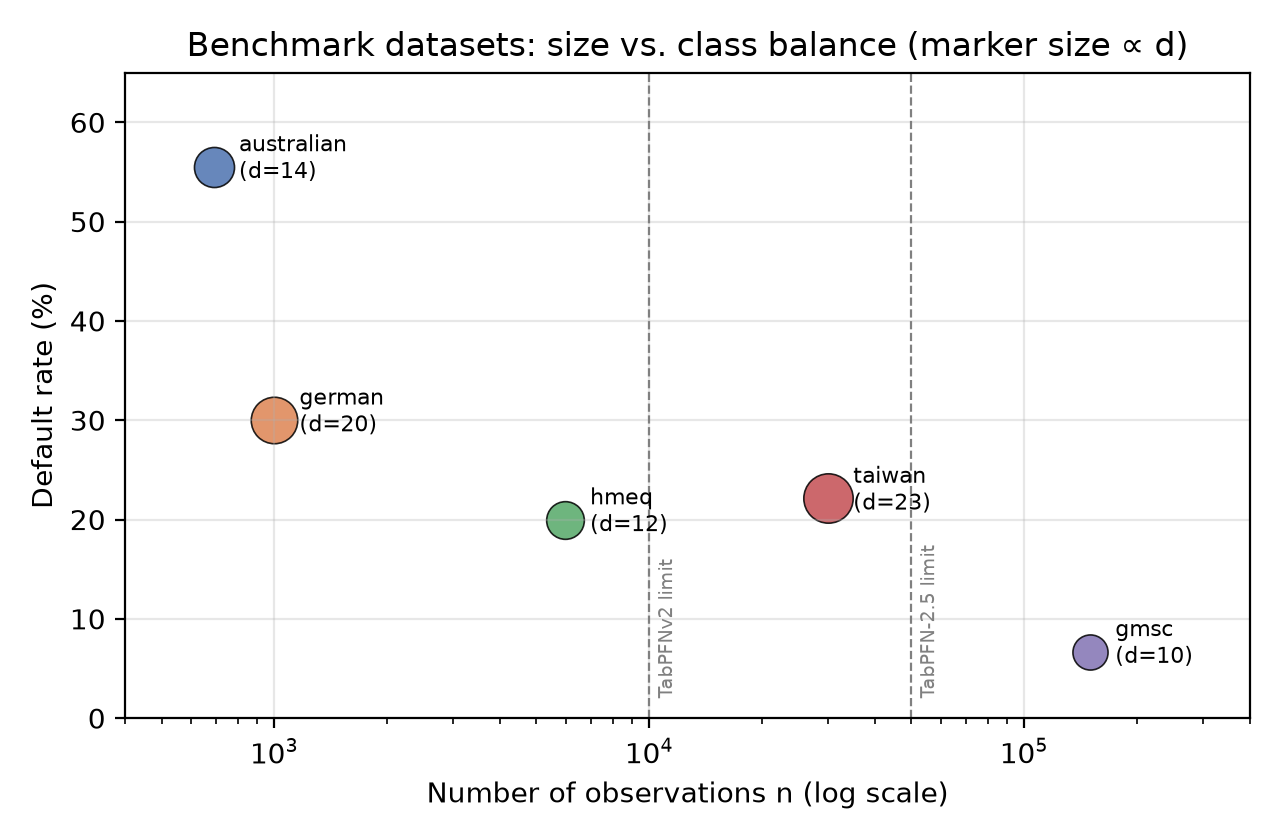

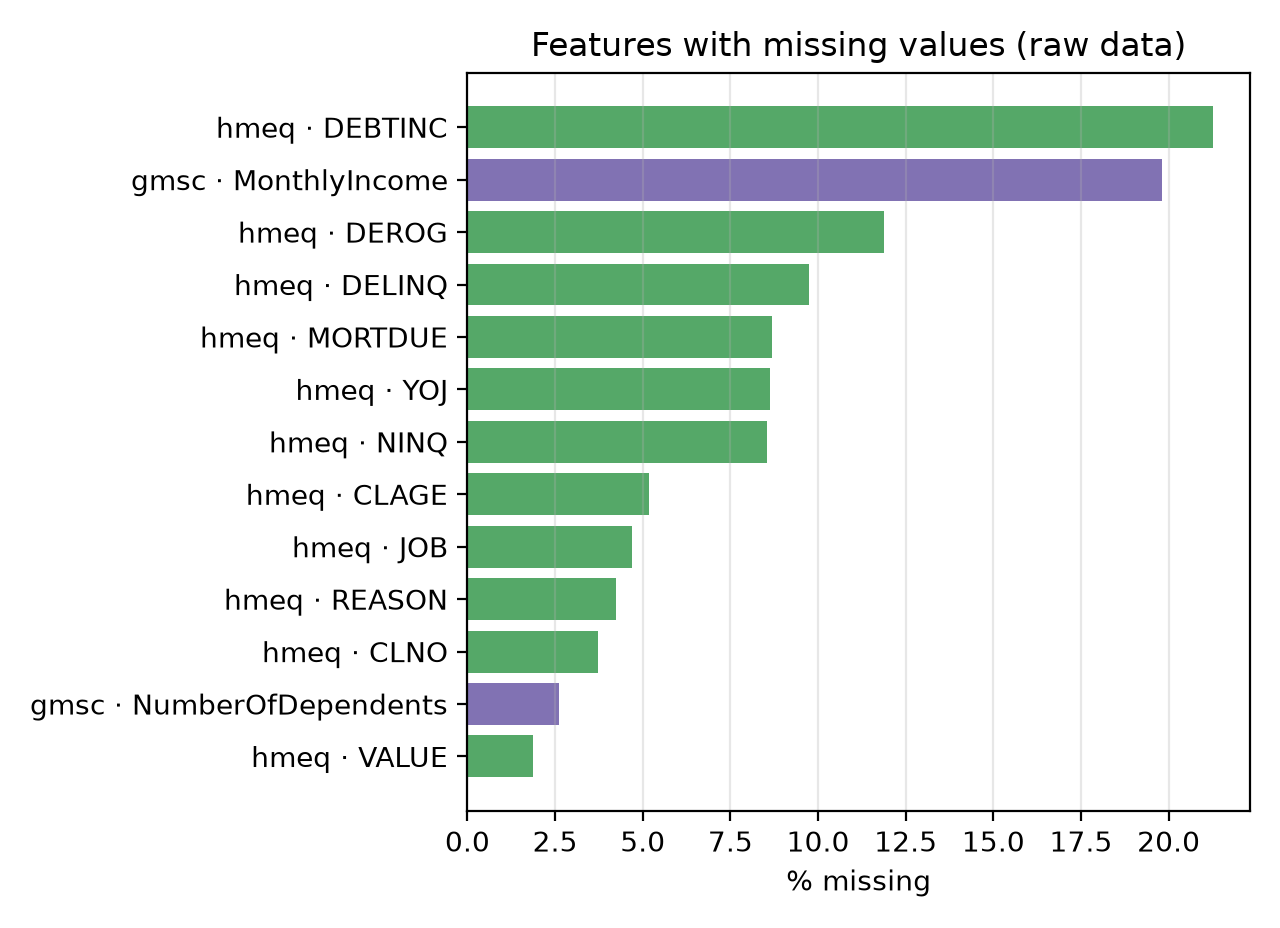

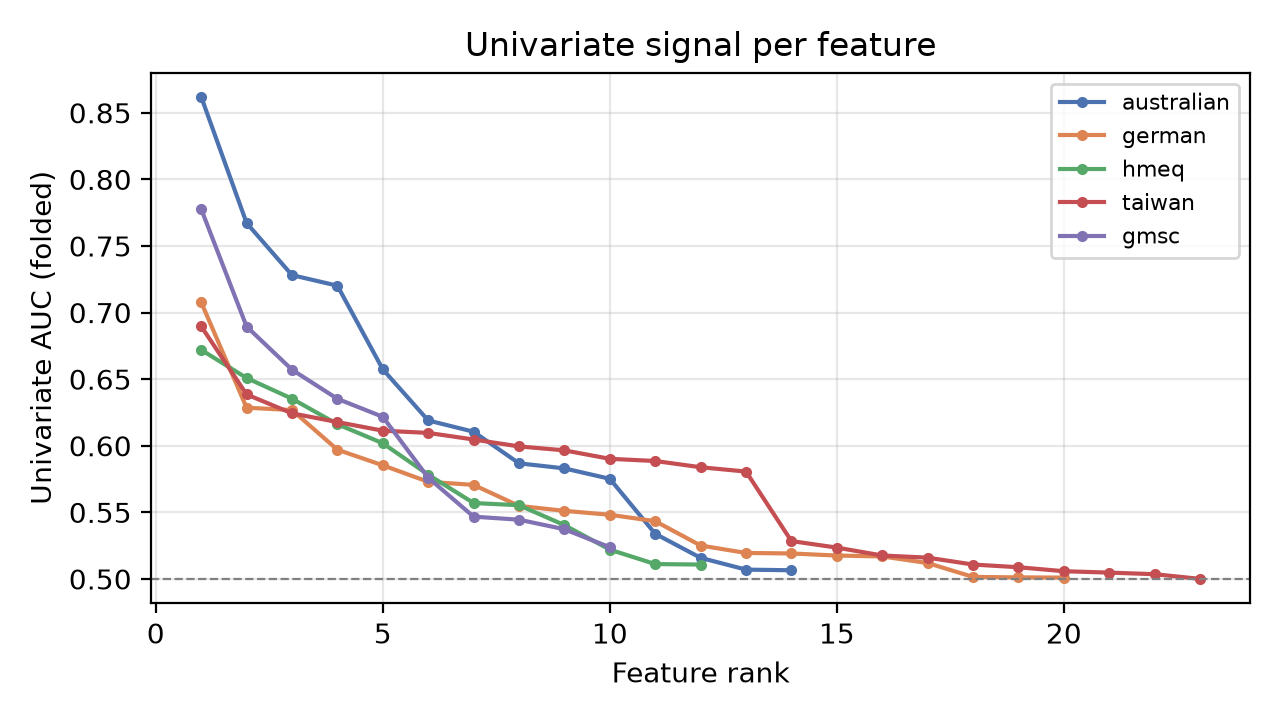

In [3]:
summary = pd.read_csv(ROOT / "results/eda/dataset_summary.csv"); display(summary)

for f in ["fig1_dataset_landscape.png", "fig2_missingness.png", "fig3_univariate_signal.png"]:
    display(Image(filename=str(ROOT / "results/eda" / f), width=620))

All five public credit datasets have 10–23 features — public credit data are low-dimensional, which is
why dimensionality is studied by *adding* uninformative features (Exp. B, axis m).

### 2.3 Splits and experimental design

In [4]:
from sml.splits import load_splits

sp = load_splits("german"); print(len(sp), "outer folds stored for German; fold 0:",
      len(sp[0]["train"]), "train /", len(sp[0]["test"]), "test")

design = pd.read_csv(ROOT / "data/processed/experiment_design.csv")

print("Experiment B design:", len(design), "feasible conditions (all reps)")

design.assign(pi=design.pi.fillna("natural")).groupby("dataset").agg(
    n_values=("n_train", lambda s: sorted(s.unique())),
    pi_values=("pi", lambda s: sorted(map(str, s.unique()))),
    m_values=("m_noise", lambda s: sorted(s.unique())))

15 outer folds stored for German; fold 0: 800 train / 200 test
Experiment B design: 450 feasible conditions (all reps)


,n_values,pi_values,m_values
dataset,,,
australian,"[250, 414]",[natural],"[0.0, 1.0, 3.0]"
german,"[250, 500, 600]",[natural],"[0.0, 1.0, 3.0]"
gmsc,"[250, 500, 1000, 2500, 5000, 10000, 20000]","[0.01, 0.02, 0.05, 0.1, natural]","[0.0, 1.0, 3.0]"
hmeq,"[250, 500, 1000, 2500]","[0.01, 0.02, 0.05, 0.1, natural]","[0.0, 1.0, 3.0]"
taiwan,"[250, 500, 1000, 2500, 5000, 10000, 20000]","[0.01, 0.02, 0.05, 0.1, natural]","[0.0, 1.0, 3.0]"


In [5]:
# Controlled condition example: GMSC, n=1000, default rate 2%, 1x d uninformative features
from sml.perturbations import Condition, make_condition

Xtr, ytr, Xte, yte, nc, cc = make_condition(datasets["gmsc"], Condition("gmsc", 1000, 0.02, 1.0, 2500))

print(Xtr.shape, "train default rate", ytr.mean(), "| test", Xte.shape, yte.mean())

Xtr.filter(like="noise_").head(3)

(1000, 20) train default rate 0.02 | test (2500, 20) 0.02


,noise_000__NumberOfTime30-59DaysPastDueNotWorse,noise_001__NumberOfTime30-59DaysPastDueNotWorse,noise_002__age,noise_003__NumberOfTimes90DaysLate,noise_004__DebtRatio,noise_005__MonthlyIncome,noise_006__MonthlyIncome,noise_007__NumberOfTimes90DaysLate,noise_008__NumberOfTimes90DaysLate,noise_009__DebtRatio
0,0.0,0.0,51.0,0.0,3058.000000,11710.0,2000.0,0.0,0.0,0.001208
1,0.0,0.0,57.0,0.0,0.213759,3797.0,NaN,3.0,0.0,0.207159
2,1.0,0.0,66.0,0.0,0.004332,14875.0,NaN,0.0,0.0,0.000000


## 3. Models
| Key | Model | Family / preprocessing | Tuning |
|---|---|---|---|
| `lr` | Logistic regression (L2) | linear: median impute + indicators, scaling, one-hot | Optuna (C) |
| `mlp` | MLP (sklearn, early stopping) | nn: as linear, quantile→normal | Optuna |
| `xgb`, `lgbm`, `cat` | XGBoost, LightGBM, CatBoost | tree: raw, NaN native, categorical codes | Optuna, early stopping |
| `tabpfn1` | TabPFN v1 (CPU) | tfm: raw; ≤1,000-row context, ≤4 bagged contexts | none (in-context) |
| `tabpfn`, `tabicl` | TabPFN-3, TabICL (GPU) | tfm | none |

Worked example on one German fold (default hyper-parameters):

In [6]:
from sml.models import fit_predict, DISPLAY
from sml.metrics import evaluate

ds = datasets["german"]; f = load_splits("german")[0]
tr, te = np.array(f["train"]), np.array(f["test"])
rows = []

for m in ["lr", "xgb", "lgbm", "cat", "mlp"]:
    p, info = fit_predict(m, ds.X.iloc[tr], ds.y.iloc[tr], ds.X.iloc[te], ds.num_cols, ds.cat_cols)
    rows.append(dict(model=DISPLAY[m], **{k: round(v, 4) for k, v in evaluate(ds.y.iloc[te], p).items()
                                          if k in ("auc", "ks", "brier", "ece", "cal_slope")},
                     seconds=info["seconds"]))

pd.DataFrame(rows)

,model,auc,ks,brier,ece,cal_slope,seconds
0,LogReg,0.7982,0.4905,0.1577,0.0796,0.8963,0.061
1,XGBoost,0.8123,0.5214,0.1566,0.0479,1.0782,0.655
2,LightGBM,0.7896,0.5048,0.1614,0.0438,0.9368,0.170
3,CatBoost,0.7467,0.4476,0.1800,0.0754,0.7252,1.056
4,MLP,0.7773,0.4262,0.1625,0.0717,0.9478,0.103


## 4. Experiments

In [8]:
if RUN_EXPERIMENTS:
    import subprocess
    subprocess.run(["bash", str(ROOT / "scripts/queue_sandbox.sh")], check=True)
    subprocess.run([sys.executable, str(ROOT / "scripts/run_analysis.py")], check=True)

ra = pd.read_csv(ROOT / "results/exp_a/results.csv")
rb = pd.concat([pd.read_csv(p) for p in sorted((ROOT / "results/exp_b").glob("results*.csv"))])

print("Exp A rows:", len(ra), "| Exp B rows:", len(rb))
print("compute (sum of fit+predict seconds):", round(ra.seconds.sum() / 60, 1), "min (A),",
      round(rb.seconds.sum() / 60, 1), "min (B)")

Exp A rows: 134 | Exp B rows: 560
compute (sum of fit+predict seconds): 11.6 min (A), 11.9 min (B)


### 4.1 Experiment A — natural conditions, tuned baselines
Every model is scored on exactly the same test rows (for Taiwan/GMSC, a fixed stratified subset on which
TabPFN v1 was evaluated).

In [9]:
for met in ["auc", "brier", "ece"]:
    print(met.upper()); display(pd.read_csv(TAB / f"expA_{met}_table.csv", index_col=0))

AUC


,LogReg,MLP,XGBoost,LightGBM,CatBoost,TabPFN-v1
dataset,,,,,,
australian,0.925 ± 0.019,0.922 ± 0.037,0.937 ± 0.023,0.935 ± 0.027,0.934 ± 0.029,0.929 ± 0.026
german,0.797 ± 0.029,0.769 ± 0.060,0.793 ± 0.048,0.780 ± 0.029,0.787 ± 0.053,0.805 ± 0.036
hmeq,0.906 ± 0.004,0.936 ± 0.007,0.973 ± 0.006,0.976 ± 0.004,0.972 ± 0.006,0.885 ± 0.016
taiwan,0.706 ± 0.019,0.764 ± 0.019,0.768 ± 0.015,0.768 ± 0.013,0.777 ± 0.016,0.755 ± 0.018
gmsc,0.796 ± 0.017,0.848 ± 0.017,0.845 ± 0.013,0.845 ± 0.013,0.837 ± 0.018,0.827 ± 0.014


BRIER


,LogReg,MLP,XGBoost,LightGBM,CatBoost,TabPFN-v1
dataset,,,,,,
australian,0.102 ± 0.018,0.107 ± 0.027,0.095 ± 0.023,0.107 ± 0.044,0.114 ± 0.037,0.097 ± 0.026
german,0.164 ± 0.014,0.170 ± 0.019,0.166 ± 0.018,0.170 ± 0.013,0.169 ± 0.029,0.158 ± 0.015
hmeq,0.081 ± 0.004,0.070 ± 0.003,0.049 ± 0.004,0.048 ± 0.003,0.050 ± 0.006,0.095 ± 0.005
taiwan,0.147 ± 0.005,0.140 ± 0.008,0.140 ± 0.003,0.146 ± 0.012,0.135 ± 0.006,0.142 ± 0.006
gmsc,0.054 ± 0.002,0.050 ± 0.002,0.052 ± 0.004,0.051 ± 0.004,0.068 ± 0.018,0.052 ± 0.002


ECE


,LogReg,MLP,XGBoost,LightGBM,CatBoost,TabPFN-v1
dataset,,,,,,
australian,0.071 ± 0.018,0.059 ± 0.014,0.063 ± 0.013,0.097 ± 0.095,0.123 ± 0.080,0.077 ± 0.011
german,0.087 ± 0.018,0.077 ± 0.021,0.098 ± 0.031,0.073 ± 0.024,0.079 ± 0.052,0.080 ± 0.026
hmeq,0.017 ± 0.003,0.033 ± 0.007,0.026 ± 0.003,0.029 ± 0.004,0.026 ± 0.006,0.040 ± 0.006
taiwan,0.056 ± 0.006,0.033 ± 0.019,0.042 ± 0.021,0.054 ± 0.053,0.018 ± 0.004,0.042 ± 0.003
gmsc,0.014 ± 0.001,0.008 ± 0.001,0.021 ± 0.023,0.021 ± 0.016,0.108 ± 0.084,0.022 ± 0.003


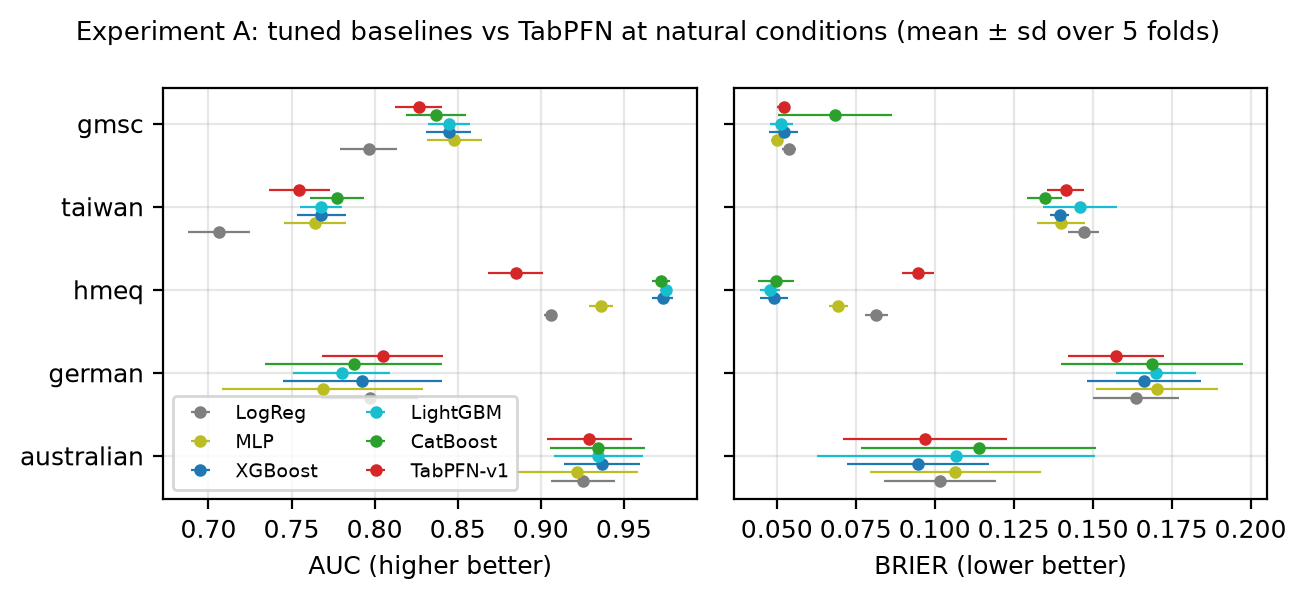

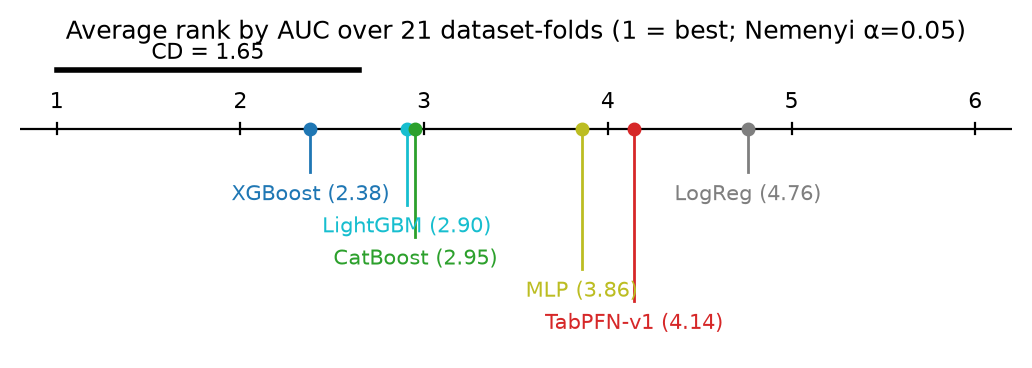

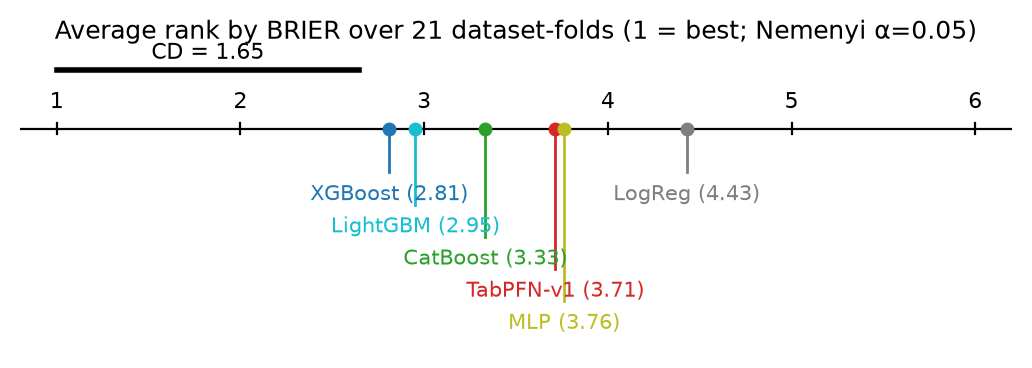

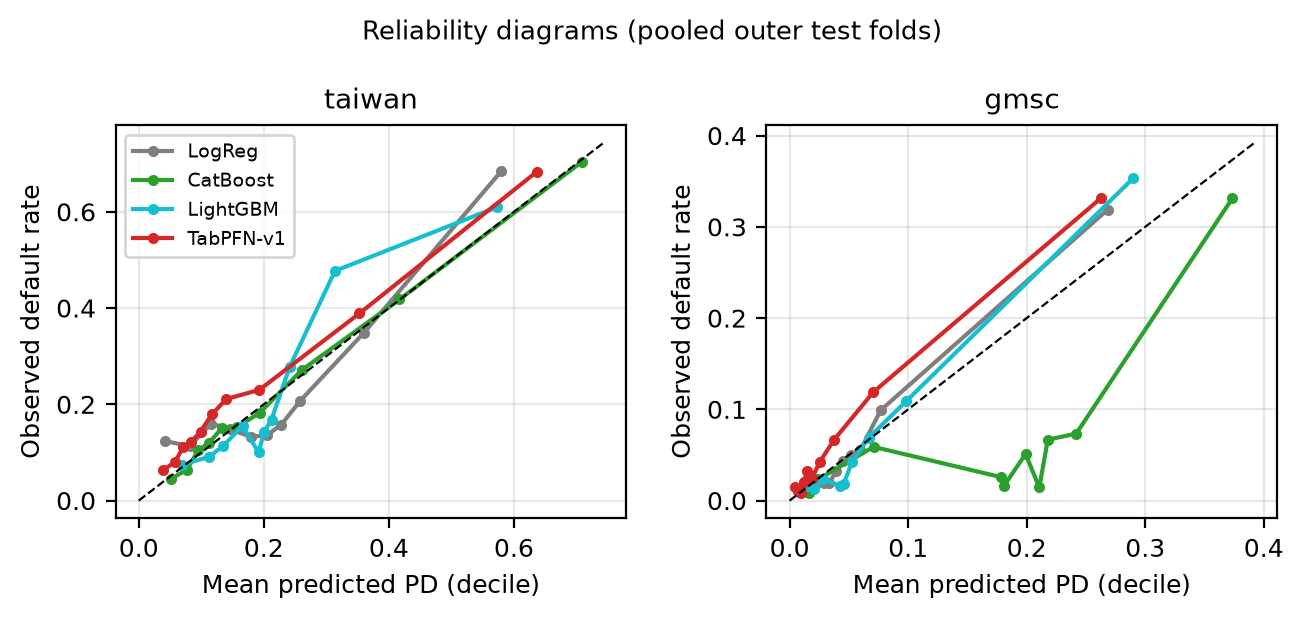

In [10]:
show("figA1_benchmark.png"); 
show("figA2_cd_auc.png", 640); 
show("figA2b_cd_brier.png", 640)
show("figA3_reliability.png", 640)

In [11]:
S = json.loads((TAB / "summary.json").read_text())

for k in ["friedman_dataset_auc", "friedman_fold_auc", "friedman_fold_brier"]:
    print(k, {kk: (round(v, 4) if isinstance(v, float) else v) for kk, v in S["expA"][k].items()})

print("\nWilcoxon-Holm, AUC (reference = best model):")
display(pd.DataFrame(S["expA"]["wilcoxon_auc"]).round(4))
print("Wilcoxon-Holm, Brier:"); display(pd.DataFrame(S["expA"]["wilcoxon_brier"]).round(4))

friedman_dataset_auc {'metric': 'auc', 'level': 'dataset', 'N': 5, 'k': 6, 'chi2': 7.7429, 'p_chi2': 0.171, 'F_ID': 1.7947, 'p_ID': 0.1598, 'avg_rank': {'xgb': 2.2, 'lgbm': 2.6, 'cat': 3.0, 'mlp': 4.2, 'tabpfn1': 4.2, 'lr': 4.8}}
friedman_fold_auc {'metric': 'auc', 'level': 'fold', 'N': 21, 'k': 6, 'chi2': 24.2381, 'p_chi2': 0.0002, 'F_ID': 6.0024, 'p_ID': 0.0001, 'avg_rank': {'xgb': 2.38, 'lgbm': 2.9, 'cat': 2.95, 'mlp': 3.86, 'tabpfn1': 4.14, 'lr': 4.76}}
friedman_fold_brier {'metric': 'brier', 'level': 'fold', 'N': 21, 'k': 6, 'chi2': 10.6871, 'p_chi2': 0.0579, 'F_ID': 2.2663, 'p_ID': 0.0535, 'avg_rank': {'xgb': 2.81, 'lgbm': 2.95, 'cat': 3.33, 'tabpfn1': 3.71, 'mlp': 3.76, 'lr': 4.43}}

Wilcoxon-Holm, AUC (reference = best model):


,ref,model,median_diff,wins_ref,n,p,p_holm
0,xgb,lr,0.0445,18,21,0.0004,0.0018
1,xgb,tabpfn1,0.0133,16,21,0.0038,0.0150
2,xgb,mlp,0.0137,16,21,0.0043,0.0150
3,xgb,cat,0.0031,13,21,0.4120,0.8240
4,xgb,lgbm,0.0002,13,21,0.5168,0.8240


Wilcoxon-Holm, Brier:


,ref,model,median_diff,wins_ref,n,p,p_holm
0,xgb,lr,-0.0077,16,21,0.0019,0.0093
1,xgb,mlp,-0.0055,16,21,0.0038,0.0150
2,xgb,tabpfn1,-0.0007,13,21,0.2029,0.6088
3,xgb,cat,-0.0005,12,21,0.2877,0.6088
4,xgb,lgbm,0.0002,10,21,1.0000,1.0000


### 4.2 Experiment B — controlled conditions (defaults, no tuning)
**Axis n (H1)**

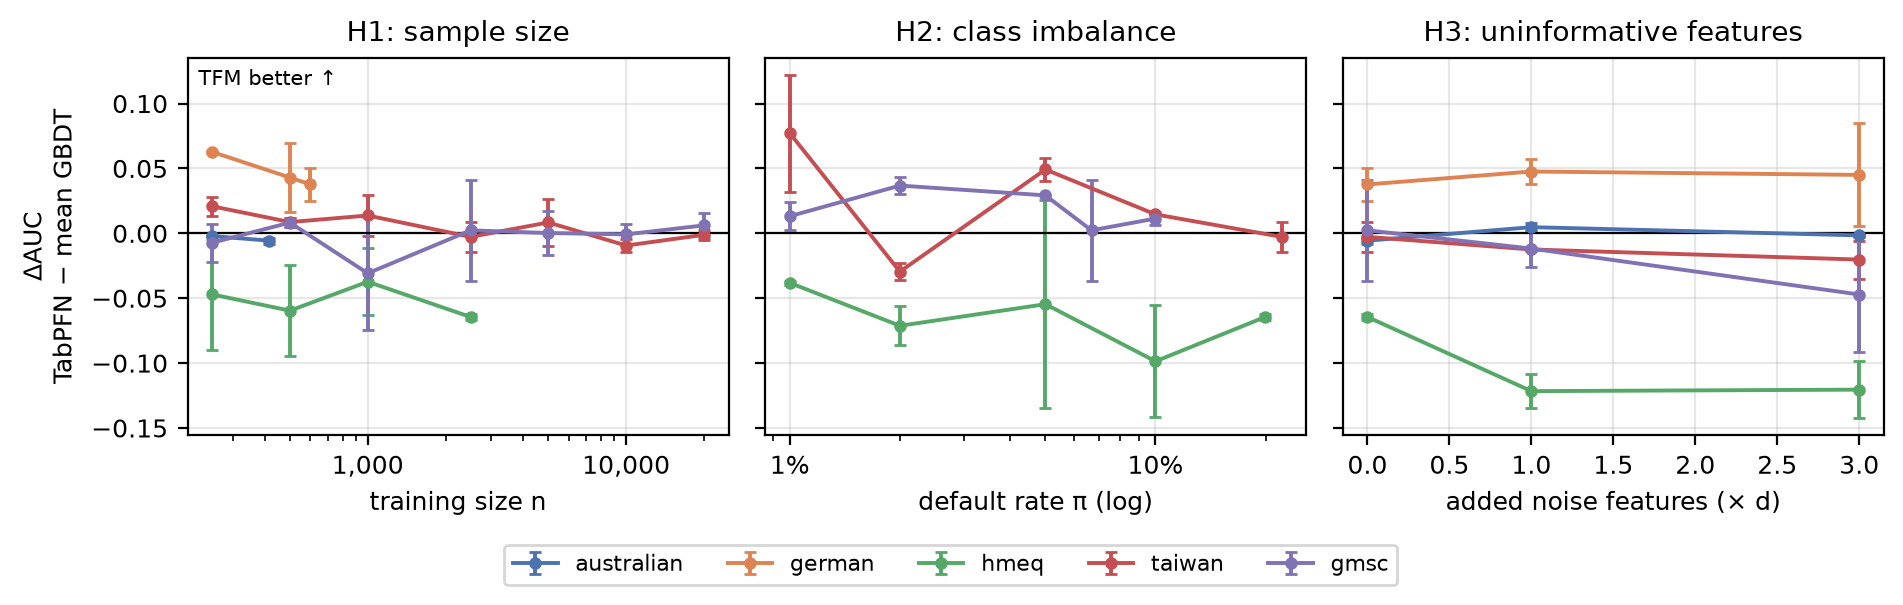

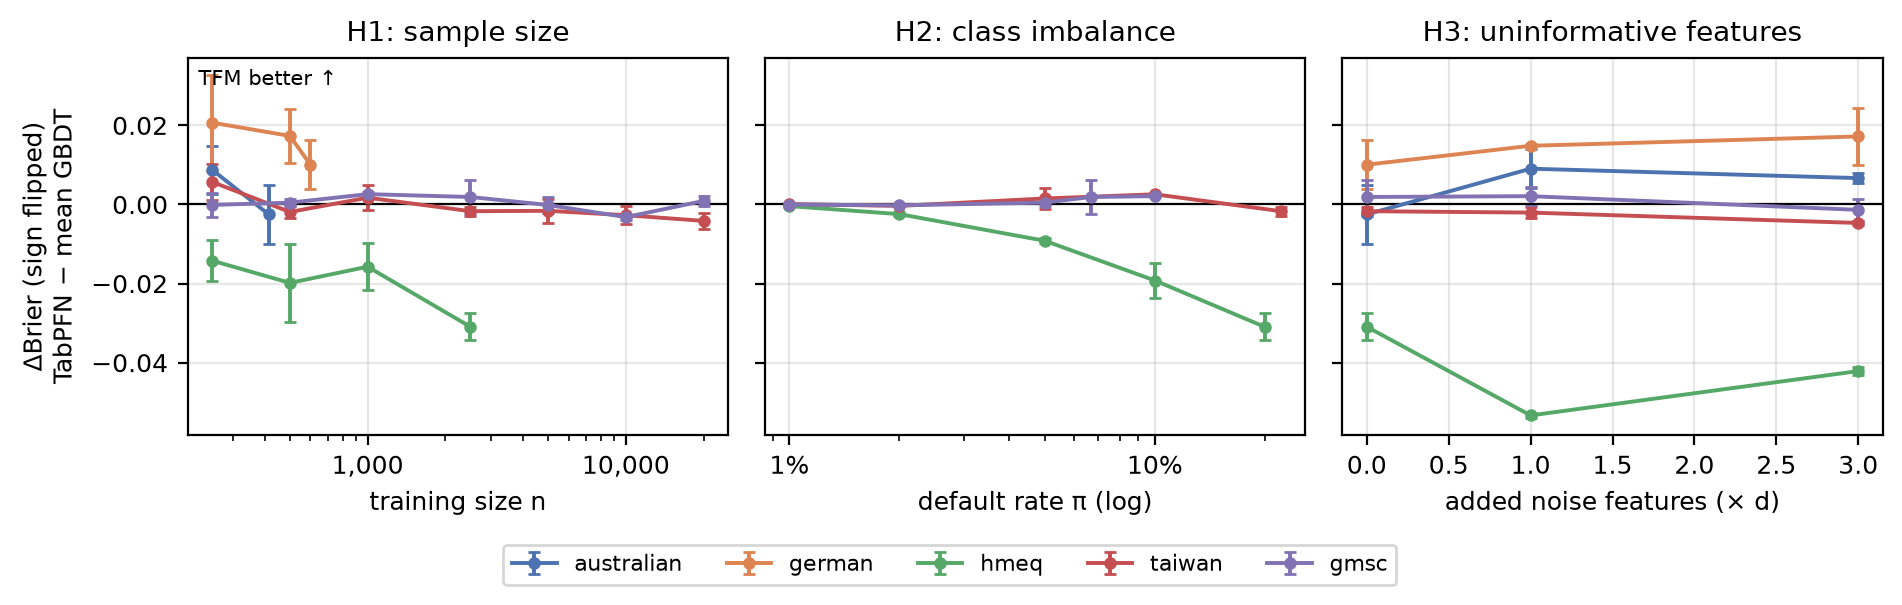

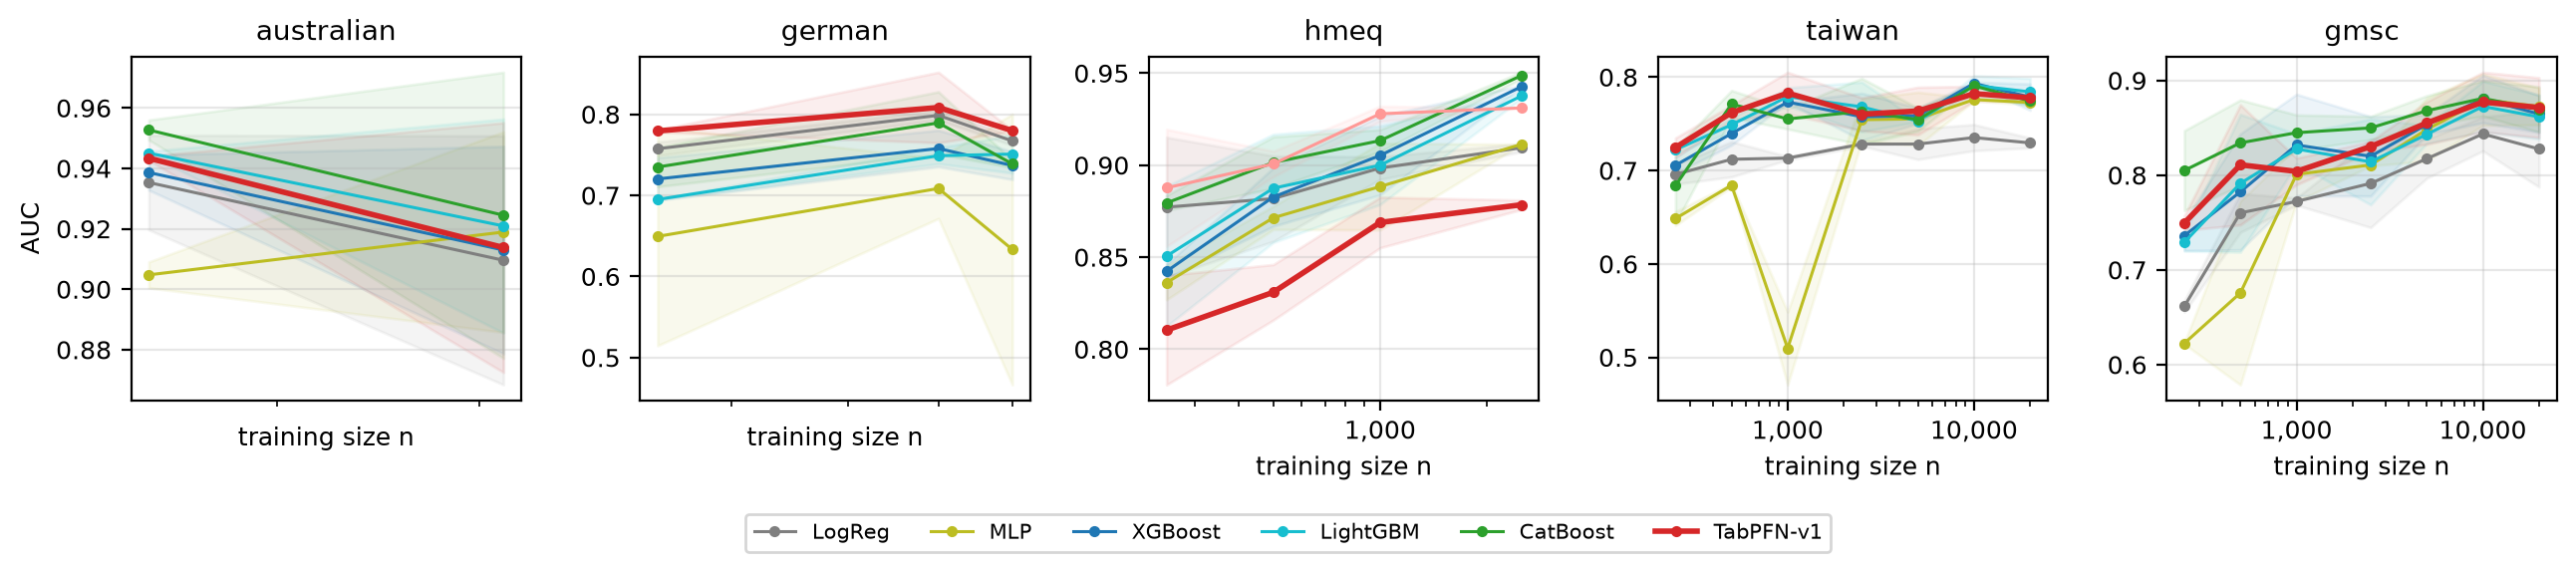

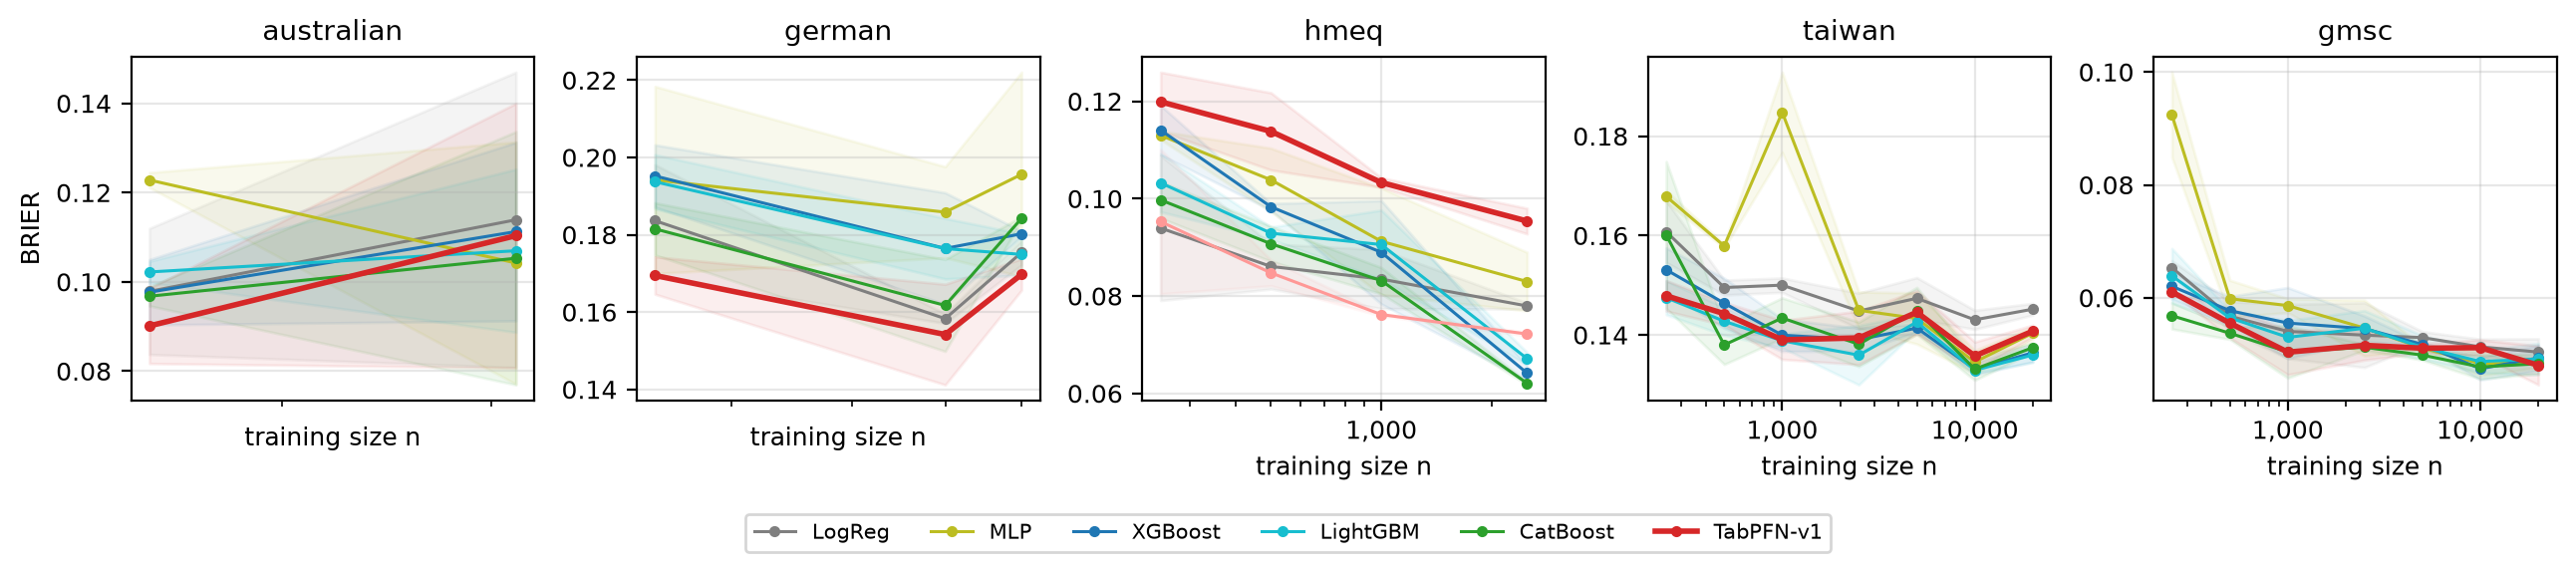

,dataset,n_train,delta_vs_mean,delta_vs_best
0,australian,250,-0.0021,-0.0093
1,australian,414,-0.0057,-0.0131
2,german,250,0.0627,0.0339
3,german,500,0.0430,0.0189
4,german,600,0.0377,0.0251
5,gmsc,250,-0.0073,-0.0555
6,gmsc,500,0.0083,-0.0232
7,gmsc,1000,-0.0308,-0.0467
8,gmsc,2500,0.0023,-0.0197
9,gmsc,5000,0.0002,-0.0130


In [12]:
show("figB_delta_auc.png", 900); show("figB_delta_brier.png", 900)
show("figB_n_auc.png", 900); show("figB_n_brier.png", 900)
display(pd.read_csv(TAB / "expB_delta_auc_n.csv").round(4))

**Axis π (H2): discrimination and calibration under low default rates**

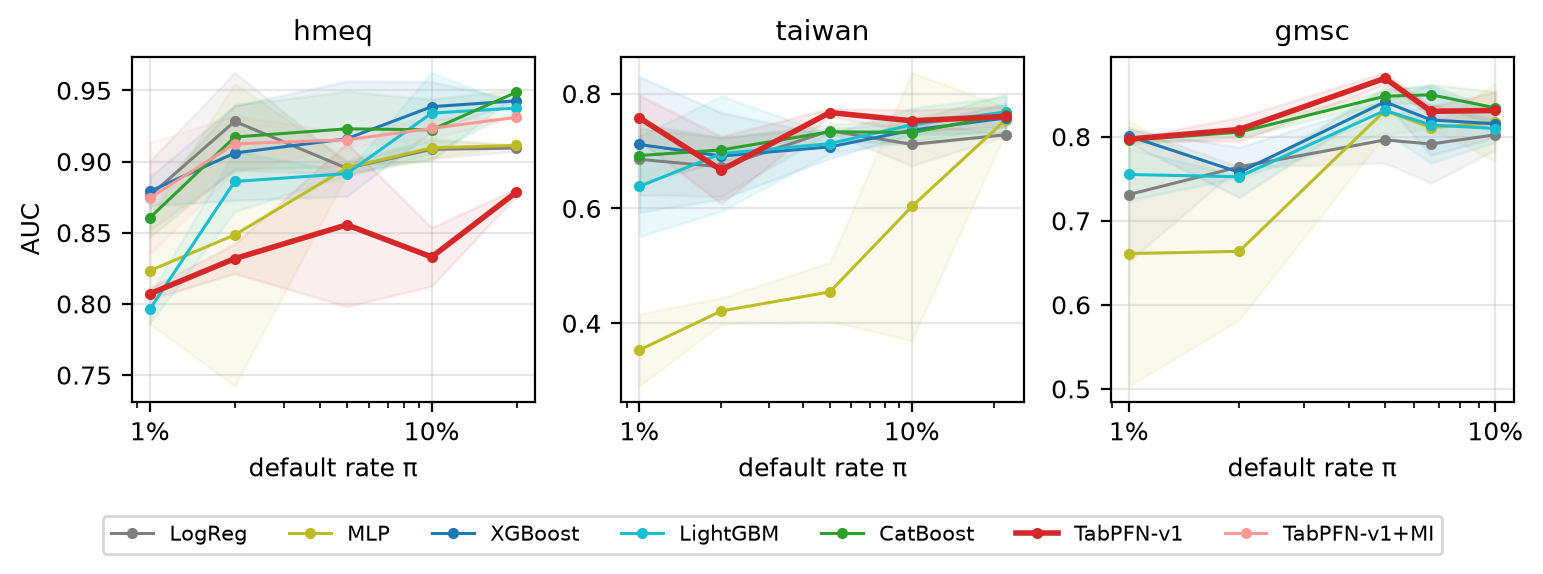

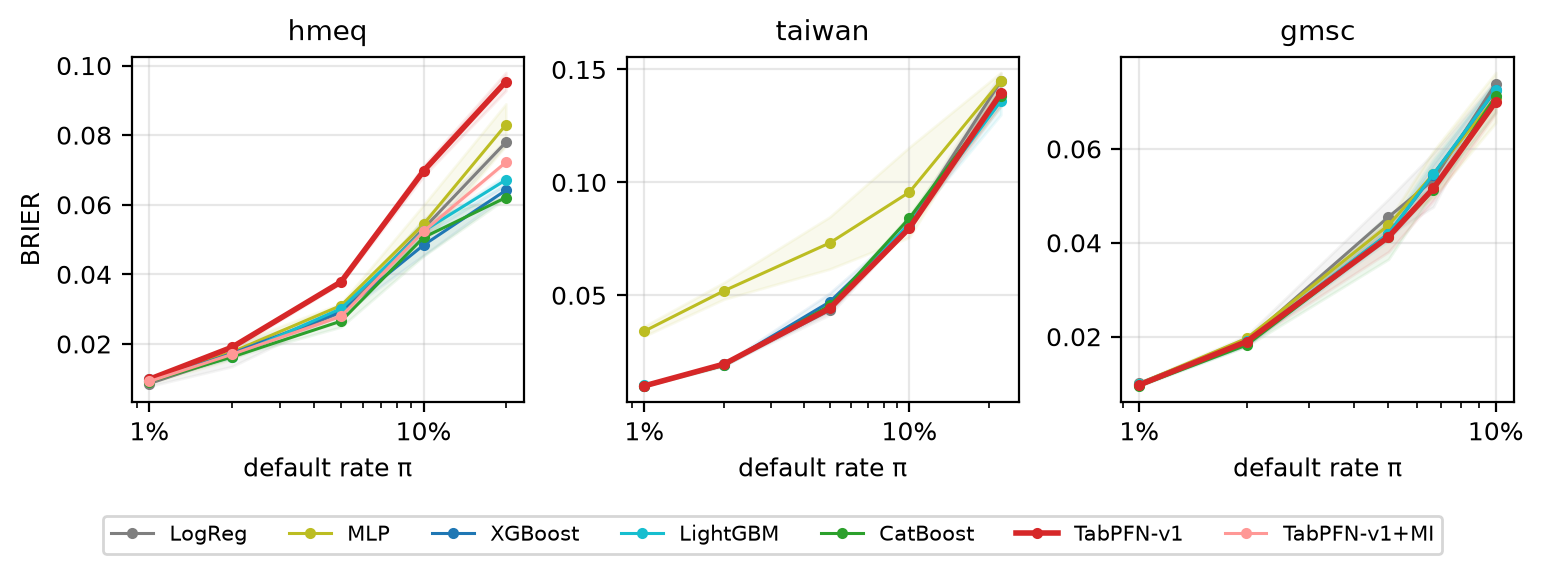

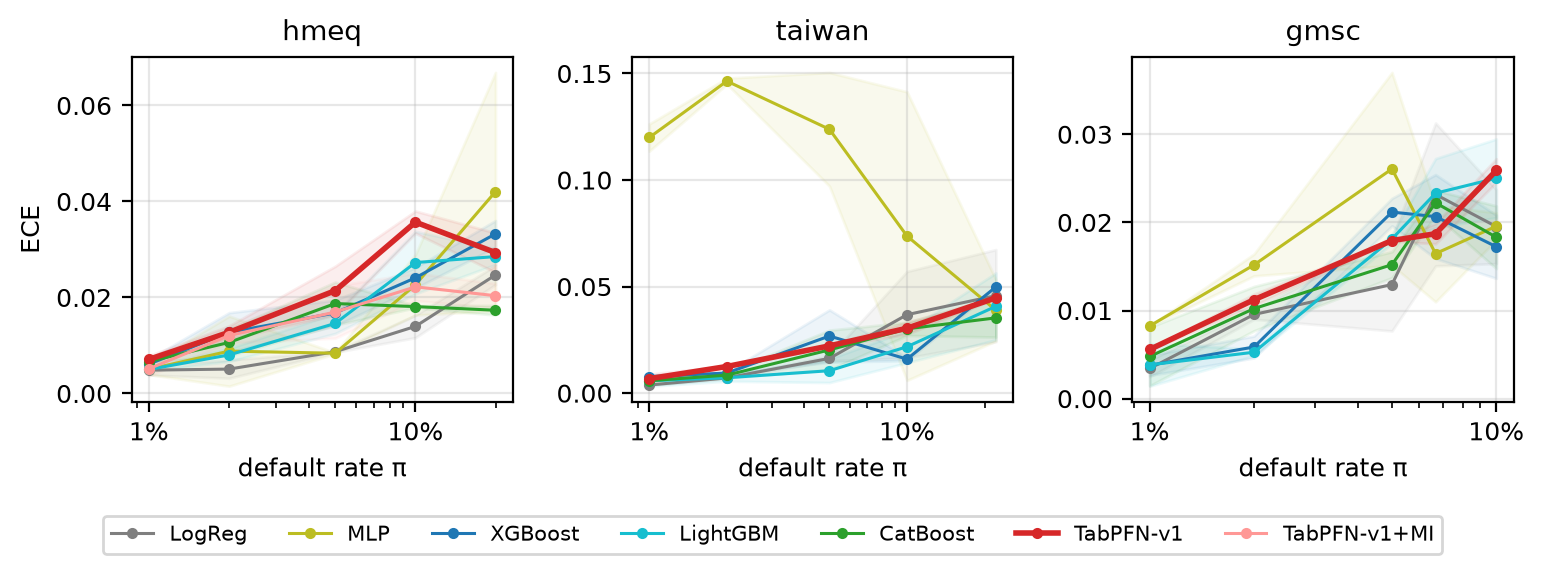

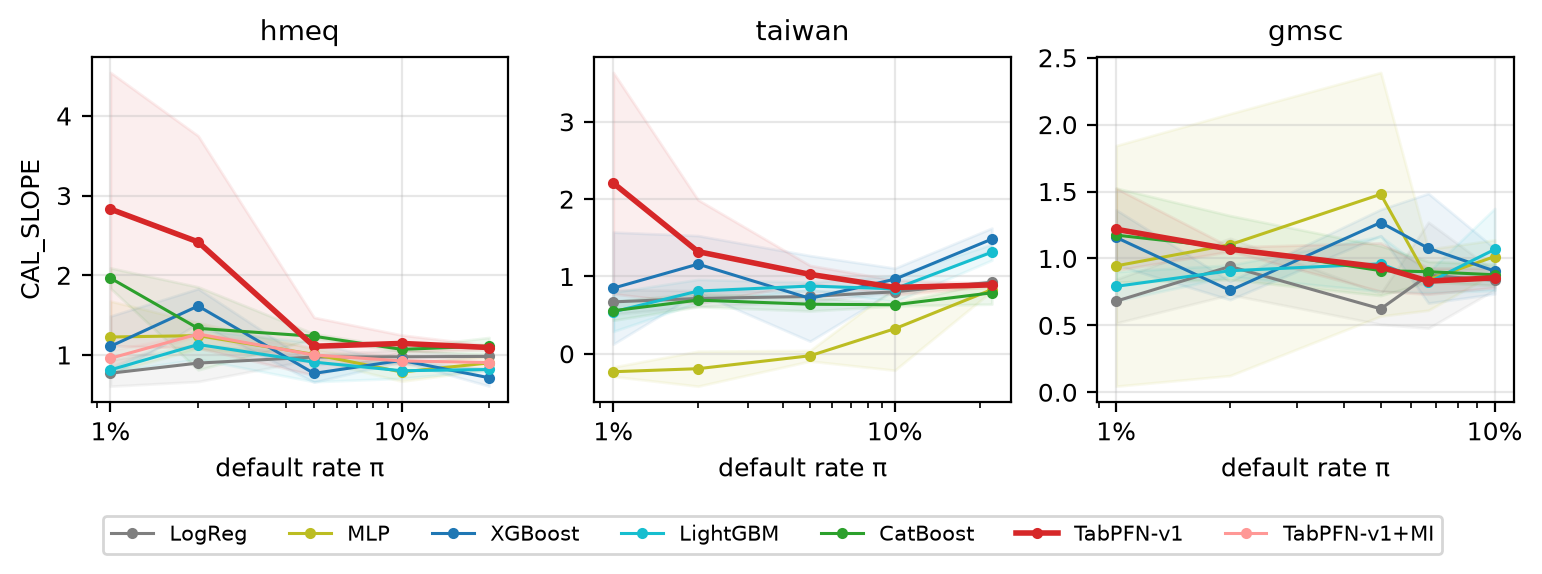

,dataset,pi_label,delta_vs_mean,delta_vs_best
0,australian,natural,-0.0057,-0.0131
1,german,natural,0.0377,0.0251
2,gmsc,0.01,0.0132,-0.0056
3,gmsc,0.02,0.0368,0.0032
4,gmsc,0.05,0.0292,0.0180
5,gmsc,0.1,0.0114,-0.0032
6,gmsc,natural,0.0023,-0.0197
7,hmeq,0.01,-0.0382,-0.0720
8,hmeq,0.02,-0.0713,-0.0854
9,hmeq,0.05,-0.0546,-0.0689


In [13]:
show("figB_pi_auc.png", 700); show("figB_pi_brier.png", 700)
show("figB_pi_ece.png", 700); show("figB_pi_calslope.png", 700)
display(pd.read_csv(TAB / "expB_delta_auc_pi.csv").round(4))

**Axis m (H3): uninformative features**

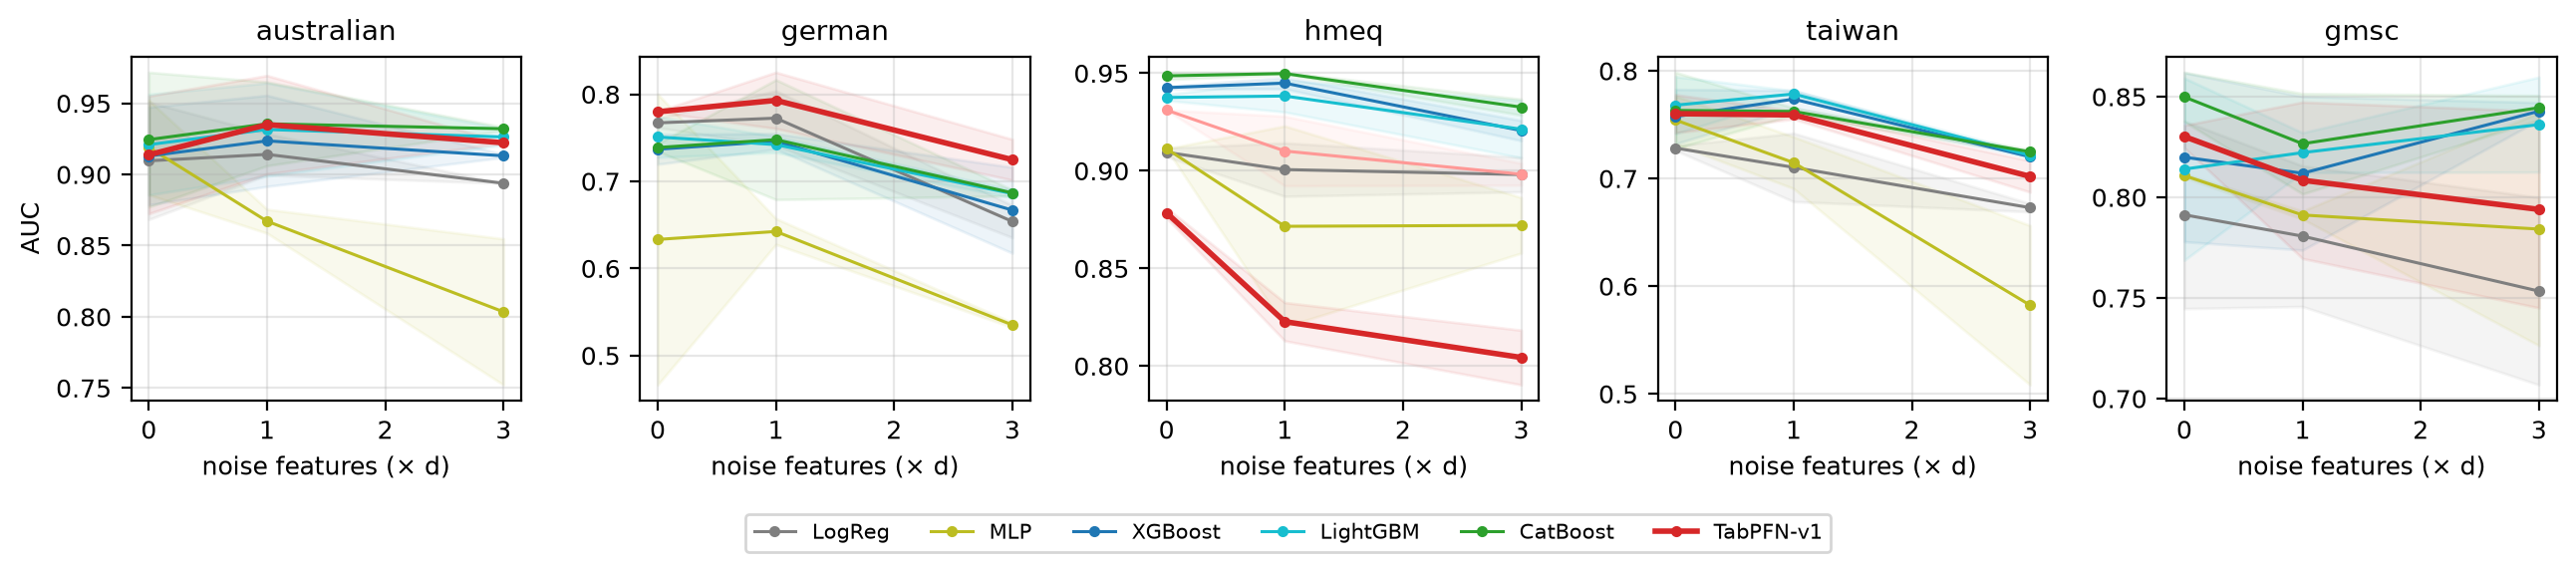

,dataset,m_noise,delta_vs_mean,delta_vs_best
0,australian,0.0,-0.0057,-0.0131
1,australian,1.0,0.0047,-0.0006
2,australian,3.0,-0.0016,-0.0098
3,german,0.0,0.0377,0.0251
4,german,1.0,0.0476,0.0185
5,german,3.0,0.0450,0.0295
6,gmsc,0.0,0.0023,-0.0197
7,gmsc,1.0,-0.0118,-0.0213
8,gmsc,3.0,-0.0472,-0.0568
9,hmeq,0.0,-0.0645,-0.0702


In [14]:
show("figB_m_auc.png", 900)
display(pd.read_csv(TAB / "expB_delta_auc_m.csv").round(4))

### 4.3 Robustness: TabPFN v1 with missing-value indicators
TabPFN v1 cannot read NaN; with median imputation it loses the signal in HMEQ's informative missingness.
Adding indicators recovers most of the gap (Exp. A) and restores the small-n advantage (Exp. B).

In [15]:
display(pd.read_csv(TAB / "expA_robustness_missing_indicators.csv").pivot(index="model", columns="dataset", values="auc").round(4))

b = pd.read_csv(TAB / "expB_all.csv"); h = b[(b.dataset == "hmeq") & b.pi.isna() & (b.m_noise == 0)]

h.groupby(["n_train", "model"]).auc.mean().unstack().round(3)

dataset,gmsc,hmeq
model,,
cat,0.8369,0.9724
lgbm,0.8447,0.9756
lr,0.7964,0.9060
mlp,0.8479,0.9364
tabpfn1,0.8266,0.8849
tabpfn1_mi,0.8279,0.9396
xgb,0.8446,0.9733


model,cat,lgbm,lr,mlp,tabpfn1,tabpfn1_mi,xgb
n_train,,,,,,,
250,0.879,0.851,0.877,0.836,0.810,0.888,0.842
500,0.901,0.887,0.882,0.871,0.831,0.901,0.883
1000,0.913,0.900,0.898,0.888,0.869,0.928,0.905
2500,0.949,0.938,0.909,0.911,0.878,0.931,0.943


## 5. Regression of the TFM–GBDT gap
$\Delta_{c} = \mathrm{metric}_{TFM,c} - \overline{\mathrm{metric}}_{GBDT,c}$ (sign flipped for loss metrics, so
$\Delta>0$ means the TFM is better), regressed on $\log_{10} n$, $\log_{10}\pi$ and $m$ with dataset fixed
effects; standard errors clustered by dataset×replicate.

In [16]:
for met in ["auc", "brier", "ece"]:
    o = S["expB"][f"ols_{met}"]
    print(f"\nΔ{met.upper()}  (n_obs={o['nobs']}, R²={o['r2']:.3f})")
    display(pd.DataFrame({"coef": o["params"], "se": o["se"], "p": o["p"]}).round(4))

print("Win-rate of TabPFN v1 vs mean / best GBDT, by training size:")
display(pd.read_csv(TAB / "expB_winrate_by_n.csv").round(3))


ΔAUC  (n_obs=90, R²=0.707)


,coef,se,p
Intercept,0.0272,0.0233,0.2420
log10_n,-0.0097,0.0090,0.2803
log10_pi,-0.0245,0.0067,0.0003
m_noise,-0.0099,0.0040,0.0132



ΔBRIER  (n_obs=90, R²=0.724)


,coef,se,p
Intercept,0.0155,0.0053,0.0033
log10_n,-0.0041,0.0019,0.0292
log10_pi,-0.0095,0.0055,0.0838
m_noise,-0.0019,0.0012,0.1109



ΔECE  (n_obs=90, R²=0.457)


,coef,se,p
Intercept,0.0479,0.0113,0.0000
log10_n,-0.0098,0.0032,0.0023
log10_pi,-0.0031,0.0023,0.1705
m_noise,0.0011,0.0018,0.5423


Win-rate of TabPFN v1 vs mean / best GBDT, by training size:


,n_bucket,delta_vs_mean,delta_vs_best
0,<=500,0.633,0.400
1,1k,0.333,0.167
2,2.5k,0.405,0.167
3,>=5k,0.417,0.250


## 6. Conclusions and reproducibility
| Hypothesis | Verdict | Evidence |
|---|---|---|
| H1 sample size | supported for calibration; for AUC once missingness is encoded | Brier/ECE slope on log n p ≤ 0.02; win-rate 63% at n ≤ 500; HMEQ+MI wins at n ≤ 1k, loses at 2.5k |
| H2 imbalance | supported, with a discrimination/calibration split | ΔAUC +0.023 per 10× drop in π (p = 0.002); calibration slope 2.2–2.8 at π = 1% |
| H3 noise features | supported | ΔAUC −0.010 per d noise features (p = 0.007) |

Limitations: TabPFN v1 (≤1,000-row context, CPU), reduced folds/trials on the two large datasets, 2 replicates.
The full discussion is in the report. Reproduce with:

```bash
pip install -r requirements.txt
python scripts/run_phase2.py                 # data checks, splits, design, EDA
bash   scripts/queue_sandbox.sh              # Phase 4 with the CPU budget used here
python scripts/run_analysis.py               # tables + figures
```
Modern TFMs (TabPFN-3, TabICL) on a GPU: `notebooks/colab_tfm_gpu.ipynb` — the same runner with
`--models tabpfn,tabicl`; `run_analysis.py` then includes them automatically.